# 🚀 Phase 2 Custom Projects Guide: Build Your Own Classical ML Portfolio (4 Beginner-Friendly Blueprints & Roadmaps)

---

## 1. Overview & The "6-Step Classical ML Recipe"

Ready to build a portfolio project without getting overwhelmed? Every great tabular ML project — whether predicting hospital readmissions, house prices, or customer upgrades — follows the exact same **6-step recipe**:

```
  1. Define Target & Metric       --> Pick Classification (PR-AUC/F1) or Regression (MAE/RMSE)
               |
               v
  2. Split Data FIRST!            --> train_test_split(..., stratify=y) BEFORE touching scalers
               |
               v
  3. Explore & Cluster (NB 02)    --> Check class balance, missingness, PCA + K-Means personas
               |
               v
  4. Build Leak-Free Pipeline     --> ColumnTransformer (Imputer + Scaler + OneHot) + Pipeline
               |
               v
  5. Baseline -> GBDT -> Optuna   --> Beat Logistic/Ridge baseline with XGBoost/LightGBM + Optuna
               |
               v
  6. Tune Cutoff & Save Joblib    --> Pick business-optimal threshold & package with README/tests
```

### 🛠️ Beginner Debugging & Troubleshooting Cheat Sheet

| Symptom You Observe | Why It Usually Happens | Exact Fix |
|---|---|---|
| Train score = **99%**, Test score = **62%** | Overfitting (too deep trees or unregularized features) | Lower `max_depth` (`3`–`6`), add `reg_lambda`, use 5-fold CV |
| Model gets **92% accuracy** on rare events | Class imbalance (92% are negative!) | Switch to **PR-AUC / Recall / F1** + `class_weight="balanced"` |
| Score drops sharply in production | **Data leakage** (scaled or selected features before splitting) | Move every step inside `sklearn.pipeline.Pipeline` |
| `ValueError: could not convert string to float` | Unencoded text categories | Add `OneHotEncoder(handle_unknown="ignore")` in `ColumnTransformer` |


## 2. Learning Objectives & Custom Project Selection Matrix

Choose **one** of these **4 beginner-friendly blueprints** to build into a complete GitHub repository:

| # | Project Blueprint | Difficulty | Time | Task Type | Primary Phase 2 Notebooks Applied |
|:-:|:---|:---:|:---:|:---|:---|
| **1** | **`HeartGuard`** — Clinical Risk & Readmission Predictor | 🟢 Beginner+ | 8–10h | Imbalanced Binary Classification | `01` Supervised, `03` Recall/PR-AUC, `04` Pipeline |
| **2** | **`HomeValue-AI`** — Smart Property Price Estimator | 🟢 Beginner+ | 6–10h | Tabular Regression + Ratios | `01` Ridge vs GBDT, `03` MAE/RMSE/$R^2$, `05` Feature Eng. |
| **3** | **`ShopPersona`** — RFM Segmentation & Upgrade Engine | 🟡 Practical | 8–12h | Clustering + Supervised Hybrid | `02` PCA/K-Means, `04` Custom Transformer, `06` Optuna |
| **4** | **`LeakageBuster`** — Tabular Pipeline & Leakage Auditor | 🟡 Practical | 8–14h | Diagnostic Tooling & Tuning | `04` `Pipeline`, `05` Feature Selection, `06` Grid vs Optuna |


## 3. Imports & Environment Check


In [1]:
import sys
import warnings
from dataclasses import dataclass, field
from typing import Any, Dict, List

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectKBest, f_classif, mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (
    mean_absolute_error,
    precision_score,
    r2_score,
    recall_score,
    root_mean_squared_error,
    silhouette_score,
)
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, RobustScaler, StandardScaler

warnings.filterwarnings("ignore", category=UserWarning)
print(f"Python {sys.version.split()[0]} | Ready to prototype all 4 Phase 2 custom projects!")


Python 3.14.10 | Ready to prototype all 4 Phase 2 custom projects!


## 4. Deterministic Configuration


In [2]:
SEED: int = 42
RNG: np.random.Generator = np.random.default_rng(SEED)

plt.rcParams["figure.figsize"] = (15, 5)
plt.rcParams["font.size"] = 10
try:
    plt.style.use("seaborn-v0_8-whitegrid")
except OSError:
    plt.rcParams["axes.grid"] = True

print(f"Deterministic seed locked: {SEED}")


Deterministic seed locked: 42


## 5. The 4 Custom Project Blueprints, Roadmaps & Live Starter Prototypes

---

### Blueprint 1: `HeartGuard` — Clinical Risk & Readmission Predictor (Imbalanced Classification)
**Plain-English Goal:** Hospitals care far more about **catching high-risk patients (`Recall`)** than raw accuracy. You will build a leakage-free classifier with balanced class weights and custom threshold tuning.

#### 5-Milestone Roadmap
1. **Milestone 1:** Split clinical vitals (`age`, `blood_pressure`, `glucose`, `prior_visits`) with `stratify=y`.
2. **Milestone 2:** Build a `Pipeline` with `SimpleImputer(median)` + `StandardScaler` + `LogisticRegression(class_weight="balanced")`.
3. **Milestone 3:** Compare against `RandomForestClassifier` and `LightGBM` using 5-fold CV **PR-AUC** & **Recall**.
4. **Milestone 4:** Sweep decision thresholds (`0.20`–`0.70`) to guarantee $\ge 85\%$ Recall.
5. **Milestone 5:** Export a clean risk-card CLI & unit tests verifying zero data leakage.

#### Starter Prototype 1 (Run & Expand!)


In [3]:
# Blueprint 1 Starter: HeartGuard Imbalanced Classification
n_pat = 800
pat_df = pd.DataFrame(
    {
        "age": RNG.integers(25, 85, n_pat).astype(float),
        "glucose": RNG.normal(115, 28, n_pat),
        "prior_visits": RNG.poisson(1.2, n_pat).astype(float),
    }
)
risk_logit = -4.2 + 0.035 * pat_df["age"] + 0.022 * pat_df["glucose"] + 0.55 * pat_df["prior_visits"]
y_pat = (RNG.random(n_pat) < (1.0 / (1.0 + np.exp(-risk_logit)))).astype(int)

Xp_tr, Xp_te, yp_tr, yp_te = train_test_split(pat_df, y_pat, test_size=0.25, stratify=y_pat, random_state=SEED)
hg_pipe = Pipeline(
    [
        ("imp", SimpleImputer(strategy="median")),
        ("sc", StandardScaler()),
        ("clf", LogisticRegression(class_weight="balanced", random_state=SEED)),
    ]
).fit(Xp_tr, yp_tr)

hg_probs = hg_pipe.predict_proba(Xp_te)[:, 1]
for thr in [0.50, 0.35]:
    preds = (hg_probs >= thr).astype(int)
    print(f"[Blueprint 1: HeartGuard] Cutoff={thr:.2f} -> Recall={recall_score(yp_te, preds)*100:.1f}% | Precision={precision_score(yp_te, preds)*100:.1f}%")


[Blueprint 1: HeartGuard] Cutoff=0.50 -> Recall=65.4% | Precision=83.2%
[Blueprint 1: HeartGuard] Cutoff=0.35 -> Recall=86.0% | Precision=78.0%


---

### Blueprint 2: `HomeValue-AI` — Smart Property Price Estimator (Tabular Regression)
**Plain-English Goal:** Predict continuous housing prices (`$`) by engineering smart domain features (`rooms_per_sqft`, `house_age`) and beating a `Ridge` linear baseline with `LightGBM` (`LGBMRegressor`).

#### 5-Milestone Roadmap
1. **Milestone 1:** Engineer domain ratios (`total_rooms / sqft`, `2026 - year_built`) and handle outliers with `RobustScaler`.
2. **Milestone 2:** Train a `Ridge` regression baseline and log `MAE`, `RMSE`, and `$R^2$`.
3. **Milestone 3:** Train `LGBMRegressor` / `XGBRegressor` to capture non-linear neighborhood & size effects.
4. **Milestone 4:** Tune `max_depth` and `learning_rate` via 5-fold CV Optuna.
5. **Milestone 5:** Plot Predicted vs Actual prices + Residual Error Histogram.

#### Starter Prototype 2 (Run & Expand!)


In [4]:
# Blueprint 2 Starter: HomeValue-AI Tabular Regression
n_homes = 900
sqft = RNG.normal(1850, 500, n_homes).clip(600, 4500)
beds = np.clip(np.round(sqft / 520 + RNG.normal(0, 0.5, n_homes)), 1, 6)
age = RNG.integers(0, 60, n_homes).astype(float)
neighborhood = RNG.choice(["Suburb", "Downtown", "Waterfront"], size=n_homes, p=[0.55, 0.30, 0.15])
loc_bonus = np.where(neighborhood == "Waterfront", 145_000, np.where(neighborhood == "Downtown", 65_000, 0))
price = 80_000 + 165 * sqft + 14_000 * beds - 1_200 * age + 0.015 * (sqft ** 1.35) + loc_bonus + RNG.normal(0, 18_000, n_homes)

home_df = pd.DataFrame({"sqft": sqft, "beds": beds, "age": age, "rooms_per_1k_sqft": beds / (sqft / 1000.0), "neighborhood": neighborhood})
Xh_tr, Xh_te, yh_tr, yh_te = train_test_split(home_df, price, test_size=0.2, random_state=SEED)

home_prep = ColumnTransformer(
    [("num", RobustScaler(), ["sqft", "beds", "age", "rooms_per_1k_sqft"]), ("cat", OneHotEncoder(handle_unknown="ignore"), ["neighborhood"])]
)
ridge_p = Pipeline([("prep", home_prep), ("m", Ridge(alpha=1.0))]).fit(Xh_tr, yh_tr)
lgbm_p = Pipeline([("prep", home_prep), ("m", lgb.LGBMRegressor(n_estimators=120, max_depth=4, random_state=SEED, verbose=-1))]).fit(Xh_tr, yh_tr)

ridge_pred, lgbm_pred = ridge_p.predict(Xh_te), lgbm_p.predict(Xh_te)
print(f"[Blueprint 2: HomeValue-AI] Ridge -> MAE=${mean_absolute_error(yh_te, ridge_pred):,.0f} | R2={r2_score(yh_te, ridge_pred):.3f}")
print(f"[Blueprint 2: HomeValue-AI] LGBM  -> MAE=${mean_absolute_error(yh_te, lgbm_pred):,.0f} | RMSE=${root_mean_squared_error(yh_te, lgbm_pred):,.0f} | R2={r2_score(yh_te, lgbm_pred):.3f}")


[Blueprint 2: HomeValue-AI] Ridge -> MAE=$13,642 | R2=0.978
[Blueprint 2: HomeValue-AI] LGBM  -> MAE=$14,788 | RMSE=$18,847 | R2=0.973


  File "C:\Users\azazb\AppData\Roaming\Python\Python314\site-packages\joblib\externals\loky\backend\context.py", line 247, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_win32()
  File "C:\Users\azazb\AppData\Roaming\Python\Python314\site-packages\joblib\externals\loky\backend\context.py", line 299, in _count_physical_cores_win32
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Python314\Lib\subprocess.py", line 555, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Python314\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
       

---

### Blueprint 3: `ShopPersona` — Customer RFM Segmentation & Upgrade Engine (Clustering + Classification)
**Plain-English Goal:** Group e-commerce shoppers by **R**ecency, **F**requency, and **M**onetary spend using `K-Means` + `PCA` (`02`), then use those segments to predict who will upgrade to VIP!

#### 5-Milestone Roadmap
1. **Milestone 1:** Compute Recency (days), Frequency (orders), and Monetary (spend) per customer.
2. **Milestone 2:** Scale with `StandardScaler` and pick optimal $K$ using the **Silhouette Score**.
3. **Milestone 3:** Project to 2D with `PCA` and label each persona (*VIP Whales*, *Steady Regulars*, *Dormant*).
4. **Milestone 4:** Feed cluster IDs/distances into a `RandomForestClassifier` to predict VIP upgrades.
5. **Milestone 5:** Build an executive persona summary table for marketing teams.

#### Starter Prototype 3 (Run & Expand!)


In [5]:
# Blueprint 3 Starter: ShopPersona RFM Clustering
n_cust = 450
rfm_df = pd.DataFrame(
    {
        "recency_days": np.concatenate([RNG.normal(8, 4, 150), RNG.normal(35, 10, 150), RNG.normal(120, 25, 150)]).clip(1, 200),
        "frequency": np.concatenate([RNG.normal(22, 5, 150), RNG.normal(8, 3, 150), RNG.normal(2, 1, 150)]).clip(1, 40),
        "monetary": np.concatenate([RNG.normal(950, 180, 150), RNG.normal(310, 80, 150), RNG.normal(75, 30, 150)]).clip(10, 1800),
    }
)
rfm_scaled = StandardScaler().fit_transform(rfm_df)
km_rfm = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(rfm_scaled)
rfm_pca = PCA(n_components=2, random_state=SEED).fit_transform(rfm_scaled)
sil = silhouette_score(rfm_scaled, km_rfm.labels_)
rfm_df["persona"] = km_rfm.labels_
print(f"[Blueprint 3: ShopPersona] 3-Cluster Silhouette Score: {sil:.3f}")
print(rfm_df.groupby("persona").mean().round(1))


[Blueprint 3: ShopPersona] 3-Cluster Silhouette Score: 0.676
         recency_days  frequency  monetary
persona                                   
0               123.9        2.1      75.1
1                 7.8       22.1     955.6
2                34.5        8.1     304.5


---

### Blueprint 4: `LeakageBuster` — Automated Tabular Pipeline & Data-Leakage Auditor
**Plain-English Goal:** Build a diagnostic tool that catches data leakage bugs automatically and benchmarks `GridSearch` vs `Optuna` tuning speed!

#### 5-Milestone Roadmap
1. **Milestone 1:** Build a synthetic pure-noise stress test to detect leaky preprocessing.
2. **Milestone 2:** Parse an arbitrary `Pipeline` and verify that all scalers/selectors live *inside* CV folds.
3. **Milestone 3:** Benchmark `GridSearchCV` vs `RandomizedSearchCV` vs `Optuna` wall-clock runtime.
4. **Milestone 4:** Flag high-variance overfitting when `Train_Score - CV_Score > 0.10`.
5. **Milestone 5:** Output a clean Pass/Fail audit report.

#### Starter Prototype 4 & Live Visual Summary Across Prototypes (Figure 1)


[Blueprint 4: LeakageBuster] Leaky Accuracy=79.2% (TRAP!) vs Honest Pipeline=58.3% (REAL)

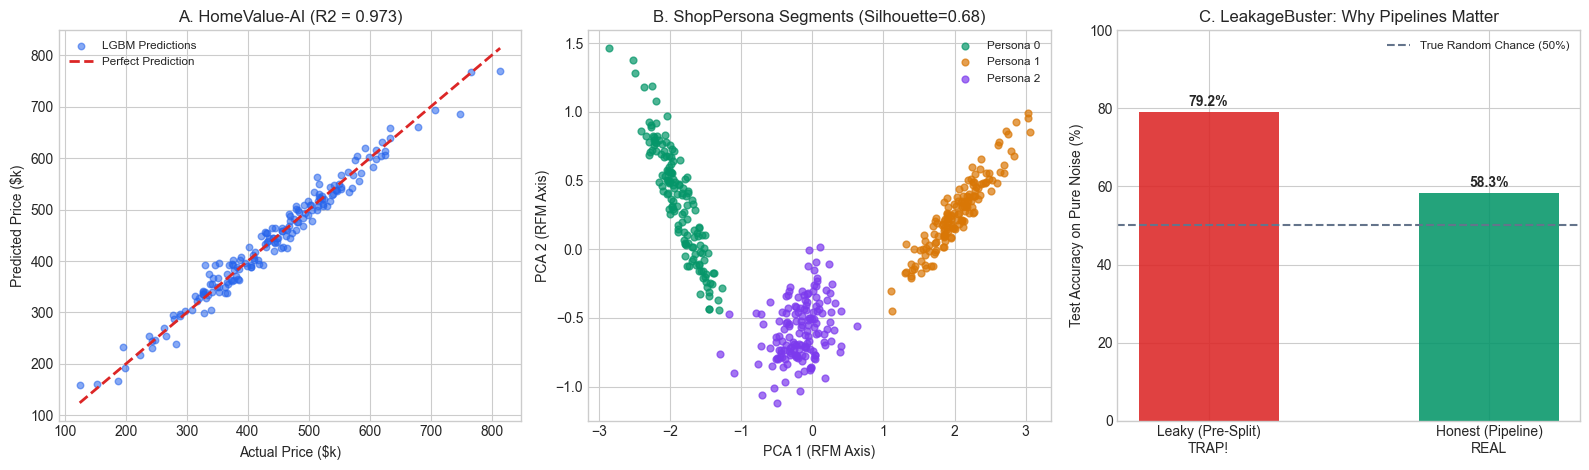

In [6]:
# Blueprint 4 Starter: LeakageBuster Audit + 3-Panel Visual Showcase
X_bad = RNG.normal(0, 1, (120, 1000))
y_bad = RNG.integers(0, 2, 120)
X_leaked = SelectKBest(f_classif, k=20).fit_transform(X_bad, y_bad)
fake_acc = float(cross_val_score(LogisticRegression(), X_leaked, y_bad, cv=5).mean())

honest_acc = float(cross_val_score(Pipeline([("sel", SelectKBest(f_classif, k=20)), ("clf", LogisticRegression())]), X_bad, y_bad, cv=5).mean())
print(f"[Blueprint 4: LeakageBuster] Leaky Accuracy={fake_acc*100:.1f}% (TRAP!) vs Honest Pipeline={honest_acc*100:.1f}% (REAL)")

# --- VISUAL FIGURE 1: Live Results from Our Custom Project Prototypes ---
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

# Panel A: HomeValue-AI Predicted vs Actual Price
ax = axes[0]
ax.scatter(yh_te / 1000, lgbm_pred / 1000, alpha=0.55, s=22, color="#2563eb", label="LGBM Predictions")
lims = [min(yh_te.min(), lgbm_pred.min()) / 1000, max(yh_te.max(), lgbm_pred.max()) / 1000]
ax.plot(lims, lims, "--", color="#dc2626", linewidth=2, label="Perfect Prediction")
ax.set_title(f"A. HomeValue-AI (R2 = {r2_score(yh_te, lgbm_pred):.3f})")
ax.set_xlabel("Actual Price ($k)")
ax.set_ylabel("Predicted Price ($k)")
ax.legend(fontsize=8.5)

# Panel B: ShopPersona 2D PCA Segments
ax = axes[1]
seg_colors = ["#059669", "#d97706", "#7c3aed"]
for k in range(3):
    m = km_rfm.labels_ == k
    ax.scatter(rfm_pca[m, 0], rfm_pca[m, 1], s=24, alpha=0.7, color=seg_colors[k], label=f"Persona {k}")
ax.set_title(f"B. ShopPersona Segments (Silhouette={sil:.2f})")
ax.set_xlabel("PCA 1 (RFM Axis)")
ax.set_ylabel("PCA 2 (RFM Axis)")
ax.legend(fontsize=8.5)

# Panel C: LeakageBuster Fake vs Honest Accuracy
ax = axes[2]
bars = ax.bar(["Leaky (Pre-Split)\nTRAP!", "Honest (Pipeline)\nREAL"], [fake_acc * 100, honest_acc * 100],
              color=["#dc2626", "#059669"], alpha=0.88, width=0.5)
ax.axhline(50.0, linestyle="--", color="#64748b", label="True Random Chance (50%)")
for b in bars:
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 1.5, f"{b.get_height():.1f}%", ha="center", fontweight="bold")
ax.set_ylim(0, 100)
ax.set_title("C. LeakageBuster: Why Pipelines Matter")
ax.set_ylabel("Test Accuracy on Pure Noise (%)")
ax.legend(fontsize=8.5)

plt.tight_layout()
plt.show()


## 6. Interactive Custom Project Planner & Portfolio Rubric Evaluator

Score your planned project against the repository's official rubric (**Functionality 30%**, **Code Quality 25%**, **Architecture 20%**, **Testing 15%**, **Documentation 10%**) and generate your starter folder tree!


In [7]:
@dataclass
class Phase2ProjectSpec:
    name: str
    slug: str
    hours: int
    skills: Dict[str, int]
    rubric_target: Dict[str, float] = field(
        default_factory=lambda: {
            "Functionality": 0.90,
            "Code Quality": 0.90,
            "Architecture": 0.88,
            "Testing": 0.85,
            "Documentation": 0.90,
        }
    )

    def weighted_score(self) -> float:
        weights = {"Functionality": 30.0, "Code Quality": 25.0, "Architecture": 20.0, "Testing": 15.0, "Documentation": 10.0}
        return sum(weights[k] * self.rubric_target[k] for k in weights)

    def folder_tree(self) -> str:
        pkg = self.slug.replace("-", "_")
        return (
            f"{self.slug}/\n"
            f"├── README.md\n"
            f"├── requirements.txt\n"
            f"├── src/{pkg}/\n"
            f"│   ├── __init__.py\n"
            f"│   ├── pipeline.py\n"
            f"│   ├── evaluate.py\n"
            f"│   └── predict.py\n"
            f"└── tests/test_pipeline.py"
        )


phase2_catalog = [
    Phase2ProjectSpec("HeartGuard", "heart-guard", 9, {"Feature Eng.": 8, "Pipelines": 10, "Tuning/Eval": 10, "Clustering": 5}),
    Phase2ProjectSpec("HomeValue-AI", "homevalue-ai", 8, {"Feature Eng.": 10, "Pipelines": 9, "Tuning/Eval": 8, "Clustering": 4}),
    Phase2ProjectSpec("ShopPersona", "shop-persona", 10, {"Feature Eng.": 8, "Pipelines": 9, "Tuning/Eval": 8, "Clustering": 10}),
    Phase2ProjectSpec("LeakageBuster", "leakage-buster", 11, {"Feature Eng.": 9, "Pipelines": 10, "Tuning/Eval": 10, "Clustering": 6}),
]

for item in phase2_catalog:
    print(f"{item.name:<16s} | Est. {item.hours:2d}h | Target Rubric Score: {item.weighted_score():.1f}/100")

print("\nStarter Folder Structure (HeartGuard):")
print(phase2_catalog[0].folder_tree())


HeartGuard       | Est.  9h | Target Rubric Score: 88.8/100
HomeValue-AI     | Est.  8h | Target Rubric Score: 88.8/100
ShopPersona      | Est. 10h | Target Rubric Score: 88.8/100
LeakageBuster    | Est. 11h | Target Rubric Score: 88.8/100

Starter Folder Structure (HeartGuard):
heart-guard/
├── README.md
├── requirements.txt
├── src/heart_guard/
│   ├── __init__.py
│   ├── pipeline.py
│   ├── evaluate.py
│   └── predict.py
└── tests/test_pipeline.py


## 7. Visual Skill Coverage & Effort Positioning (Figure 2)


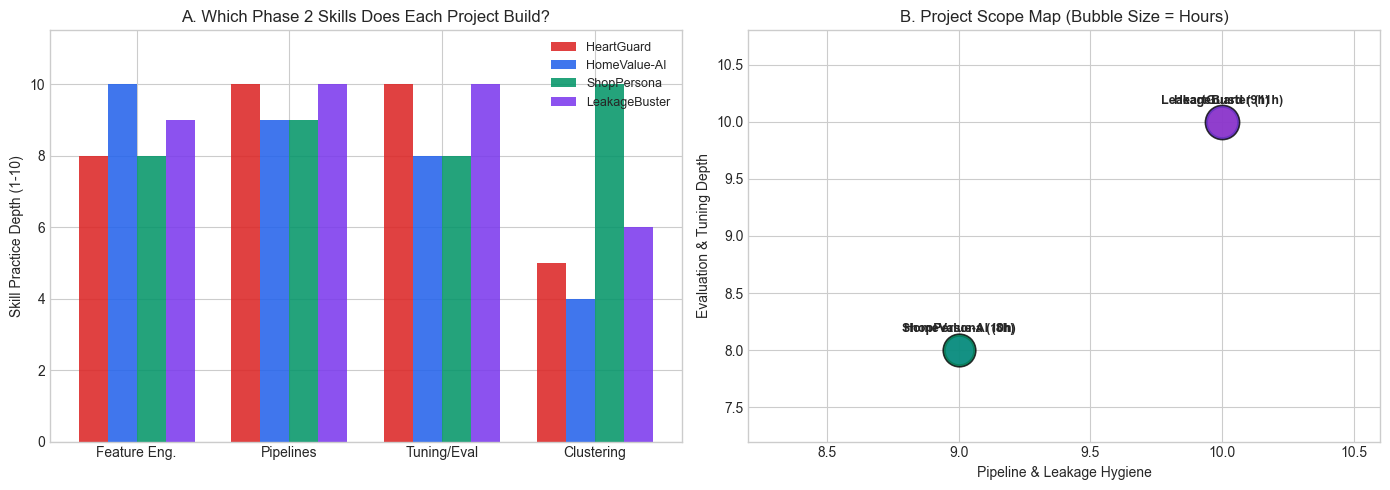

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

pillars = list(phase2_catalog[0].skills.keys())
x = np.arange(len(pillars))
width = 0.19
colors = ["#dc2626", "#2563eb", "#059669", "#7c3aed"]

for i, spec in enumerate(phase2_catalog):
    axes[0].bar(x + (i - 1.5) * width, [spec.skills[p] for p in pillars], width=width, label=spec.name, color=colors[i], alpha=0.88)

axes[0].set_xticks(x)
axes[0].set_xticklabels(pillars)
axes[0].set_ylim(0, 11.5)
axes[0].set_ylabel("Skill Practice Depth (1-10)")
axes[0].set_title("A. Which Phase 2 Skills Does Each Project Build?")
axes[0].legend(fontsize=9)

pipe_scores = [s.skills["Pipelines"] for s in phase2_catalog]
eval_scores = [s.skills["Tuning/Eval"] for s in phase2_catalog]
sizes = [s.hours * 55 for s in phase2_catalog]
for i, spec in enumerate(phase2_catalog):
    axes[1].scatter(pipe_scores[i], eval_scores[i], s=sizes[i], color=colors[i], alpha=0.8, edgecolors="black", linewidth=1.2)
    axes[1].annotate(f"{spec.name} ({spec.hours}h)", (pipe_scores[i], eval_scores[i]),
                     textcoords="offset points", xytext=(0, 13), ha="center", fontsize=9, fontweight="bold")

axes[1].set_xlim(8.2, 10.6)
axes[1].set_ylim(7.2, 10.8)
axes[1].set_xlabel("Pipeline & Leakage Hygiene")
axes[1].set_ylabel("Evaluation & Tuning Depth")
axes[1].set_title("B. Project Scope Map (Bubble Size = Hours)")

plt.tight_layout()
plt.show()


## 8. Guided Customization Exercise: Add `LightGBM` to `HeartGuard`

Extend Blueprint 1 (`HeartGuard`) by replacing `LogisticRegression` with `LGBMClassifier(class_weight="balanced")` inside the exact same leak-proof `Pipeline`, and compare Recall at cutoff `0.40`.


In [9]:
hg_lgbm_pipe = Pipeline(
    [
        ("imp", SimpleImputer(strategy="median")),
        ("sc", StandardScaler()),
        ("clf", lgb.LGBMClassifier(n_estimators=100, max_depth=3, class_weight="balanced", random_state=SEED, verbose=-1)),
    ]
).fit(Xp_tr, yp_tr)

lgbm_hg_probs = hg_lgbm_pipe.predict_proba(Xp_te)[:, 1]
lgbm_hg_preds = (lgbm_hg_probs >= 0.40).astype(int)
rec_val = recall_score(yp_te, lgbm_hg_preds)
assert rec_val > 0.50, "Expected balanced LightGBM to catch majority of positive cases"
print(f"Exercise PASSED -> HeartGuard LGBM Recall@0.40 = {rec_val*100:.1f}% | Precision = {precision_score(yp_te, lgbm_hg_preds)*100:.1f}%")


Exercise PASSED -> HeartGuard LGBM Recall@0.40 = 77.2% | Precision = 80.8%


## 9. Challenge Problem: Automated Portfolio Readiness Gate

Validate that all 4 custom project specs pass the repository's `85/100` quality bar and include unit tests (`Testing >= 0.80`).


In [10]:
def verify_phase2_portfolio_ready(specs: List[Phase2ProjectSpec]) -> Dict[str, float]:
    summary: Dict[str, float] = {}
    for s in specs:
        score = round(s.weighted_score(), 1)
        assert score >= 85.0 and s.rubric_target["Testing"] >= 0.80, f"{s.name} failed readiness gate"
        summary[s.name] = score
    return summary


gate_scores = verify_phase2_portfolio_ready(phase2_catalog)
print("Challenge PASSED -> All 4 Phase 2 Blueprints Cleared Readiness Gate:", gate_scores)


Challenge PASSED -> All 4 Phase 2 Blueprints Cleared Readiness Gate: {'HeartGuard': 88.8, 'HomeValue-AI': 88.8, 'ShopPersona': 88.8, 'LeakageBuster': 88.8}


## 10. Portfolio Submission Checklist & Next Steps

Before jumping to **Phase 3: Deep Learning**, verify your custom Phase 2 project has:
- [ ] `train_test_split` executed **before** any scaling, encoding, imputation, or clustering
- [ ] Complete preprocessing + estimator wrapped inside a single `sklearn.pipeline.Pipeline`
- [ ] A clear baseline (`LogisticRegression` or `Ridge`) compared fairly against a boosted tree (`XGBoost` / `LightGBM`)
- [ ] At least 2 diagnostic plots (Confusion Matrix / ROC / PR Curve / Feature Importance) in your `README.md`
- [ ] `pytest` unit tests checking pipeline output shapes and zero-leakage assertions

**Next Phase:** Proceed to [`Phase 3: Deep Learning & Neural Networks →`](../03-deep-learning/)
